# 07 — Reference baselines on validation (Week 3, Sprint 2)

Scores the reference baselines on the **validation** split with the shared evaluation module
`src/evaluation/metrics.py`. The test split is **not** opened here (it is used once, at the end of Sprint 2).

**Input:** `data/processed/model_dataset.parquet` + `model_dataset_meta.json` (notebook 06, builder v1.1).
**Samples:** for horizon h, origin t is used when `ok_h{h}` (all 60 input minutes and the target valid) and
`split_h{h} == "val"` (fitting uses `"train"`). Every model is scored on exactly the same samples.

**Baselines** (all forecasts in kW, target P(t + h)):

| Model | Forecast | Fitted on |
|---|---|---|
| `persistence` | P(t) | — |
| `pers_mod5_static` | P(t) + mean change of P over h for the origin's minute-mod-5 class | train |
| `pers_mod5_rolling` | same, mean over the past 7 days of valid pairs whose target is already observed (causal) | past only |
| `seasonal_naive_1d` | P(t + h − 1440), persistence where that minute is invalid | — |
| `ar_lags` | P(t) + ridge regression of P(t + h) − P(t) on P(t − k) − P(t), k = 1..59 (direct, one model per h) | train |
| `ar_lags_cal` | `ar_lags` + minute-mod-5 one-hot + hour sin/cos | train |
| `ar_lags_cal_cov` | `ar_lags_cal` + 1- and 5-minute covariate changes + allocation gap (gpus_alloc − n_gpu_equiv) | train |

The ridge penalty is chosen on validation from a small grid (reported). `ar_lags_cal_cov` vs `ar_lags_cal` is
the out-of-sample check of the H3 covariate gain (notebook 05: in-sample ΔR² +0.03 to +0.04).

| Cell | Content | Needs |
|---|---|---|
| 1 | Setup, paths, imports, versions | — |
| 2 | Load the dataset; sample indices per horizon | 1 |
| 3 | Self-test of the metrics module on toy data | 1 |
| 4 | Persistence (check against notebook 06) | 2 |
| 5 | Persistence with minute-mod-5 correction (static, rolling) | 2 |
| 6 | Daily seasonal naive | 2 |
| 7 | Linear AR (ridge), three feature sets, penalty chosen on validation | 2 |
| 8 | Comparison table on validation, Diebold–Mariano vs persistence, H3 check | 4–7 |
| 9 | Figures: skill per model and horizon; one validation window | 8 |
| 10 | Save tables, predictions and summary (optional W&B) | 8 |
| 11 | Summary | 8, 10 |

Export after saving (Cmd+S): `%run ../src/tools/nb_outputs_to_md.py 07_baselines.ipynb`.


In [1]:
# Cell 1: setup, paths, imports, versions (needed by every cell)
import sys, json, time, platform
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
from evaluation import metrics as M

DATA = ROOT / "data" / "processed" / "model_dataset.parquet"
META = ROOT / "data" / "processed" / "model_dataset_meta.json"
OUT = ROOT / "reports" / "baselines"
FIG = ROOT / "reports" / "figures" / "baselines"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
HORIZONS = (1, 5, 15)
INPUT_LEN = 60
SPLIT_EVAL = "val"          # the test split stays closed in this notebook
DM_LAG = 60                 # Newey-West lags for the Diebold-Mariano test (minutes)
ROLL_WINDOW = 7 * 1440      # window of the rolling mod-5 correction (minutes)
ALPHAS = [0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]
USE_WANDB = False           # True: log the validation table to Weights & Biases (needs wandb login)

pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(240)
for p in (DATA, META, ROOT / "src" / "evaluation" / "metrics.py"):
    print(f"{'OK     ' if p.exists() else 'MISSING'} {p.relative_to(ROOT)}")
print(f"python {platform.python_version()} | polars {pl.__version__} | numpy {np.__version__} | "
      f"matplotlib {matplotlib.__version__}")


OK      data/processed/model_dataset.parquet
OK      data/processed/model_dataset_meta.json
OK      src/evaluation/metrics.py
python 3.11.16 | polars 1.44.2 | numpy 2.4.6 | matplotlib 3.11.2


In [2]:
# Cell 2: load the dataset; arrays and sample indices per horizon (needs cell 1)
md = pl.read_parquet(DATA)
meta = json.loads(META.read_text())
print(f"rows {md.height:,} x {md.width} | builder {meta['version']} | built {meta['created_utc']} UTC")
n = md.height
P = md["P_kW"].to_numpy().astype(float)              # NaN where null
VALID = md["valid"].to_numpy()
MOD5 = md["mod5"].to_numpy().astype(int)
L24 = md["L24_kW"].to_numpy().astype(float)
HSIN = md["hour_sin"].to_numpy()
HCOS = md["hour_cos"].to_numpy()
TLOC = md["minute_local"].to_numpy()
THR = {h: meta["thresholds"][str(h)]["rel_p95"] for h in HORIZONS}

IDX = {}   # IDX[h][split] = origin indices t of usable samples
for h in HORIZONS:
    ok = md[f"ok_h{h}"].to_numpy()
    sp = np.array(md[f"split_h{h}"].to_list(), dtype=object)
    IDX[h] = {s: np.flatnonzero(ok & (sp == s)) for s in ("train", "val", "test")}
    assert np.isfinite(P[IDX[h]["train"] + h]).all() and np.isfinite(P[IDX[h]["val"] + h]).all()
rows = [{"h": h, **{s: len(IDX[h][s]) for s in ("train", "val", "test")},
         "matches meta": all(len(IDX[h][s]) == meta["sample_counts"][str(h)][s]["samples"] for s in ("train", "val", "test")),
         "rel p95": round(THR[h], 4)} for h in HORIZONS]
print(pl.DataFrame(rows))
print(f"evaluation split: {SPLIT_EVAL} (test is not used in this notebook)")

def truth(h, s=SPLIT_EVAL):
    t = IDX[h][s]
    return P[t + h], P[t]

PRED = {h: {} for h in HORIZONS}   # PRED[h][model] = forecasts on IDX[h][SPLIT_EVAL]


rows 303,840 x 68 | builder 1.1 (2026-10-08) | built 2026-10-09 09:06:52 UTC
shape: (3, 6)
┌─────┬────────┬───────┬───────┬──────────────┬─────────┐
│ h   ┆ train  ┆ val   ┆ test  ┆ matches meta ┆ rel p95 │
│ --- ┆ ---    ┆ ---   ┆ ---   ┆ ---          ┆ ---     │
│ i64 ┆ i64    ┆ i64   ┆ i64   ┆ bool         ┆ f64     │
╞═════╪════════╪═══════╪═══════╪══════════════╪═════════╡
│ 1   ┆ 196700 ┆ 42575 ┆ 42575 ┆ true         ┆ 0.0295  │
│ 5   ┆ 196668 ┆ 42567 ┆ 42567 ┆ true         ┆ 0.0399  │
│ 15  ┆ 196588 ┆ 42547 ┆ 42547 ┆ true         ┆ 0.0568  │
└─────┴────────┴───────┴───────┴──────────────┴─────────┘
evaluation split: val (test is not used in this notebook)


In [3]:
# Cell 3: self-test of the metrics module on toy data (needs cell 1)
rng = np.random.default_rng(0)
y = rng.normal(30, 5, 5000)
p0 = y + rng.normal(0, 0.5, 5000)
yh = y + rng.normal(0, 0.2, 5000)
T = {}
T["MAE of a known error"] = abs(M.mae([1, 2, 3], [2, 2, 5]) - 1.0) < 1e-12
T["RMSE of a known error"] = abs(M.rmse([0, 0], [3, 4]) - np.sqrt(12.5)) < 1e-12
T["sMAPE 0 for perfect forecast"] = M.smape(y, y) == 0.0
T["sMAPE 0/0 counts as 0"] = M.smape([0.0, 1.0], [0.0, 1.0]) == 0.0
T["R2 perfect = 1"] = abs(M.r2(y, y) - 1) < 1e-12
T["skill of persistence = 0"] = abs(M.evaluate(y, p0, p0)["skill_MAE"]) < 1e-12
T["R2_delta of persistence <= 0"] = M.r2_delta(y, p0, p0) <= 0
T["better model has positive skill"] = M.evaluate(y, yh, p0)["skill_MAE"] > 0
dm = M.dm_test(y, yh, p0, lag=5)
T["DM: clearly better model -> stat < 0, p < 0.01"] = dm["DM_stat"] < 0 and dm["DM_p"] < 0.01
yh2 = p0 + rng.normal(0, 1e-3, 5000)
T["DM: near-identical forecasts -> p > 0.01"] = M.dm_test(y, yh2, p0, lag=5)["DM_p"] > 0.01
rs = M.ramp_scores(np.array([10., 10, 10, 10]), np.array([12., 10, 12, 10]), np.array([10., 10, 10, 10]),
                   np.array([10., 10, 10, 10]), np.array([1., 1, 0, 0]), 0.1)
T["ramp precision/recall/F1 on a known case"] = (rs["ramp_precision"], rs["ramp_recall"], rs["ramp_F1"]) == (0.5, 0.5, 0.5)
try:
    M.evaluate([1.0, np.nan], [1.0, 1.0], [1.0, 1.0]); T["NaN input rejected"] = False
except ValueError:
    T["NaN input rejected"] = True
for k, v in T.items():
    print(f"{'ok  ' if v else 'FAIL'} {k}")
METRICS_OK = all(T.values())
print("metrics self-test ok:", METRICS_OK)


ok   MAE of a known error
ok   RMSE of a known error
ok   sMAPE 0 for perfect forecast
ok   sMAPE 0/0 counts as 0
ok   R2 perfect = 1
ok   skill of persistence = 0
ok   R2_delta of persistence <= 0
ok   better model has positive skill
ok   DM: clearly better model -> stat < 0, p < 0.01
ok   DM: near-identical forecasts -> p > 0.01
ok   ramp precision/recall/F1 on a known case
ok   NaN input rejected
metrics self-test ok: True


In [4]:
# Cell 4: persistence (needs cell 2)
for h in HORIZONS:
    y, p0 = truth(h)
    PRED[h]["persistence"] = p0.copy()
    m = M.mae(y, p0)
    ref = meta["persistence_samples"][str(h)][SPLIT_EVAL]["MAE"]
    print(f"h={h:>2}: n {len(y):,} | MAE {m:.4f} kW | notebook 06 {ref:.4f} | same: {abs(m - ref) < 1e-9}")


h= 1: n 42,575 | MAE 0.2866 kW | notebook 06 0.2866 | same: True
h= 5: n 42,567 | MAE 0.4299 kW | notebook 06 0.4299 | same: True
h=15: n 42,547 | MAE 0.6048 kW | notebook 06 0.6048 | same: True


In [5]:
# Cell 5: persistence with a minute-mod-5 correction, static (train) and rolling (causal, past 7 days) (needs cell 2)
rows = []
for h in HORIZONS:
    # static: mean change per origin class on train samples
    tr = IDX[h]["train"]
    dtr = P[tr + h] - P[tr]
    c = np.array([dtr[MOD5[tr] == m].mean() for m in range(5)])
    t = IDX[h][SPLIT_EVAL]
    PRED[h]["pers_mod5_static"] = P[t] + c[MOD5[t]]
    rows += [{"h": h, "mod5 of origin": m, "train mean change (kW)": round(c[m], 4),
              "train n": int((MOD5[tr] == m).sum())} for m in range(5)]

    # rolling: pairs (s, s+h) with both ends valid; a pair becomes known at time s+h;
    # correction at origin t = mean change of known pairs of the same class with s+h in (t - W, t]
    pair = np.zeros(n, dtype=bool)
    pair[:n - h] = VALID[:n - h] & VALID[h:]
    s = np.flatnonzero(pair)
    d = P[s + h] - P[s]
    corr = np.zeros(len(t))
    for m in range(5):
        sm = s[MOD5[s] == m]
        dm_ = d[MOD5[s] == m]
        avail = sm + h
        cs = np.concatenate([[0.0], np.cumsum(dm_)])
        hi = np.searchsorted(avail, t, side="right")                 # avail <= t
        lo = np.searchsorted(avail, t - ROLL_WINDOW, side="right")   # avail > t - W
        cnt = hi - lo
        mean = np.where(cnt > 0, (cs[hi] - cs[lo]) / np.maximum(cnt, 1), 0.0)
        sel = MOD5[t] == m
        corr[sel] = np.where(cnt[sel] >= 100, mean[sel], 0.0)
    PRED[h]["pers_mod5_rolling"] = P[t] + corr
    y, p0 = truth(h)
    print(f"h={h:>2}: MAE persistence {M.mae(y, p0):.4f} | static {M.mae(y, PRED[h]['pers_mod5_static']):.4f} | "
          f"rolling {M.mae(y, PRED[h]['pers_mod5_rolling']):.4f} kW")
print("\nstatic correction (train):")
print(pl.DataFrame(rows))
print("note: for h = 5 and 15 origin and target share the mod-5 class, so the correction is only a mean drift")


h= 1: MAE persistence 0.2866 | static 0.2839 | rolling 0.2707 kW
h= 5: MAE persistence 0.4299 | static 0.4299 | rolling 0.4302 kW
h=15: MAE persistence 0.6048 | static 0.6047 | rolling 0.6059 kW

static correction (train):
shape: (15, 4)
┌─────┬────────────────┬────────────────────────┬─────────┐
│ h   ┆ mod5 of origin ┆ train mean change (kW) ┆ train n │
│ --- ┆ ---            ┆ ---                    ┆ ---     │
│ i64 ┆ i64            ┆ f64                    ┆ i64     │
╞═════╪════════════════╪════════════════════════╪═════════╡
│ 1   ┆ 0              ┆ 0.1291                 ┆ 39341   │
│ 1   ┆ 1              ┆ -0.0041                ┆ 39340   │
│ 1   ┆ 2              ┆ 0.0036                 ┆ 39339   │
│ 1   ┆ 3              ┆ 0.0054                 ┆ 39339   │
│ 1   ┆ 4              ┆ -0.1345                ┆ 39341   │
│ 5   ┆ 0              ┆ -0.0007                ┆ 39333   │
│ 5   ┆ 1              ┆ -0.0006                ┆ 39333   │
│ 5   ┆ 2              ┆ -0.0006          

In [6]:
# Cell 6: daily seasonal naive P(t + h - 1440), persistence where that minute is invalid (needs cell 2)
for h in HORIZONS:
    t = IDX[h][SPLIT_EVAL]
    j = t + h - 1440
    ok = (j >= 0) & VALID[np.clip(j, 0, n - 1)]
    PRED[h]["seasonal_naive_1d"] = np.where(ok, P[np.clip(j, 0, n - 1)], P[t])
    y, p0 = truth(h)
    print(f"h={h:>2}: MAE {M.mae(y, PRED[h]['seasonal_naive_1d']):.4f} kW | fallback to persistence on "
          f"{(~ok).mean():.2%} of samples")


h= 1: MAE 4.8896 kW | fallback to persistence on 3.24% of samples
h= 5: MAE 4.8958 kW | fallback to persistence on 3.23% of samples
h=15: MAE 4.9088 kW | fallback to persistence on 3.21% of samples


In [7]:
# Cell 7: linear AR (ridge, direct per horizon) with three feature sets; penalty chosen on validation (needs cell 2)
COV = ["util_gpu_mean", "util_mem_mean", "temp_gpu_mean", "temp_mem_mean", "mem_used_sum", "mem_free_sum",
       "n_gpu_equiv", "gpus_alloc", "active_gpu_jobs", "active_jobs", "queued_gpu_jobs", "queued_jobs"]
DCOV = {c: md[c].to_numpy().astype(float) for c in [f"d{k}_{v}" for v in COV for k in (1, 5)]}
ALLOC_GAP = md["gpus_alloc"].to_numpy().astype(float) - md["n_gpu_equiv"].to_numpy().astype(float)

def features(t, kind):
    """Feature matrix for origins t. All columns use minutes <= t only."""
    cols, names = [], []
    lags = np.stack([P[t - k] - P[t] for k in range(1, INPUT_LEN)], axis=1)
    cols.append(lags); names += [f"lag{k}" for k in range(1, INPUT_LEN)]
    if kind in ("cal", "cal_cov"):
        cols.append(np.stack([(MOD5[t] == m).astype(float) for m in range(1, 5)] + [HSIN[t], HCOS[t]], axis=1))
        names += [f"mod5_{m}" for m in range(1, 5)] + ["hour_sin", "hour_cos"]
    if kind == "cal_cov":
        cols.append(np.stack([DCOV[c][t] for c in DCOV] + [ALLOC_GAP[t]], axis=1))
        names += list(DCOV) + ["alloc_gap"]
    X = np.concatenate(cols, axis=1)
    if not np.isfinite(X).all():
        raise ValueError(f"non-finite features ({kind}): {np.argwhere(~np.isfinite(X))[:5]}")
    return X, names

def ridge_fit(X, y, alphas):
    mu, sd = X.mean(0), X.std(0)
    sd[sd == 0] = 1.0
    Z = (X - mu) / sd
    ym = y.mean()
    G, b = Z.T @ Z, Z.T @ (y - ym)
    out = {}
    for a in alphas:
        beta = np.linalg.solve(G + a * np.eye(G.shape[0]), b)
        out[a] = (mu, sd, ym, beta)
    return out

def ridge_predict(model, X):
    mu, sd, ym, beta = model
    return ym + ((X - mu) / sd) @ beta

AR_INFO, rows = {}, []
for h in HORIZONS:
    tr, va = IDX[h]["train"], IDX[h][SPLIT_EVAL]
    y_tr = P[tr + h] - P[tr]
    y_va, p0_va = truth(h)
    for kind in ("lags", "cal", "cal_cov"):
        name = {"lags": "ar_lags", "cal": "ar_lags_cal", "cal_cov": "ar_lags_cal_cov"}[kind]
        t0 = time.time()
        Xtr, names = features(tr, kind)
        Xva, _ = features(va, kind)
        fits = ridge_fit(Xtr, y_tr, ALPHAS)
        scores = {a: M.mae(y_va, p0_va + ridge_predict(f, Xva)) for a, f in fits.items()}
        best = min(scores, key=scores.get)
        PRED[h][name] = p0_va + ridge_predict(fits[best], Xva)
        r2_tr = M.r2(y_tr, ridge_predict(fits[best], Xtr))
        AR_INFO[(h, name)] = {"alpha": best, "n_features": Xtr.shape[1], "names": names,
                              "beta_std": fits[best][3], "R2_delta_train": r2_tr}
        rows.append({"h": h, "model": name, "features": Xtr.shape[1], "alpha": best,
                     **{f"val MAE a={a:g}": round(v, 4) for a, v in scores.items()},
                     "R2_delta train": round(r2_tr, 4), "s": round(time.time() - t0, 1)})
print(pl.DataFrame(rows))
print("\nlargest standardised coefficients of ar_lags_cal_cov (h = 5):")
info = AR_INFO[(5, "ar_lags_cal_cov")]
order = np.argsort(-np.abs(info["beta_std"]))[:15]
print(pl.DataFrame({"feature": [info["names"][i] for i in order],
                    "beta (per train std)": [round(float(info["beta_std"][i]), 4) for i in order]}))


shape: (9, 12)
┌─────┬─────────────────┬──────────┬─────────┬───────────────┬─────────────┬──────────────┬───────────────┬────────────────┬─────────────────┬────────────────┬─────┐
│ h   ┆ model           ┆ features ┆ alpha   ┆ val MAE a=0.1 ┆ val MAE a=1 ┆ val MAE a=10 ┆ val MAE a=100 ┆ val MAE a=1000 ┆ val MAE a=10000 ┆ R2_delta train ┆ s   │
│ --- ┆ ---             ┆ ---      ┆ ---     ┆ ---           ┆ ---         ┆ ---          ┆ ---           ┆ ---            ┆ ---             ┆ ---            ┆ --- │
│ i64 ┆ str             ┆ i64      ┆ f64     ┆ f64           ┆ f64         ┆ f64          ┆ f64           ┆ f64            ┆ f64             ┆ f64            ┆ f64 │
╞═════╪═════════════════╪══════════╪═════════╪═══════════════╪═════════════╪══════════════╪═══════════════╪════════════════╪═════════════════╪════════════════╪═════╡
│ 1   ┆ ar_lags         ┆ 59       ┆ 1000.0  ┆ 0.2673        ┆ 0.2673      ┆ 0.2673       ┆ 0.2673        ┆ 0.2673         ┆ 0.2678          ┆ 0.1842      

In [8]:
# Cell 8: comparison on validation; Diebold-Mariano vs persistence; H3 out-of-sample check (needs cells 4-7)
MODELS = ["persistence", "pers_mod5_static", "pers_mod5_rolling", "seasonal_naive_1d",
          "ar_lags", "ar_lags_cal", "ar_lags_cal_cov"]
res = []
for h in HORIZONS:
    t = IDX[h][SPLIT_EVAL]
    y, p0 = truth(h)
    ramp = md[f"ramp_h{h}"].to_numpy().astype(float)[t]
    for mname in MODELS:
        r = M.evaluate(y, PRED[h][mname], p0, l24=L24[t], ramp=ramp, thr=THR[h],
                       mod5_target=MOD5[(t + h) % n] if h == 1 else None, dm_lag=DM_LAG)
        res.append({"h": h, "model": mname, **r})
VAL = pl.DataFrame(res)
show = ["h", "model", "n", "MAE", "RMSE", "sMAPE", "R2", "R2_delta", "skill_MAE", "skill_RMSE",
        "MAE_ramp", "MAE_normal", "ramp_recall", "ramp_F1", "DM_stat", "DM_p"]
print(VAL.select(show).with_columns([pl.col(c).round(4) for c in show[3:] if c != "n"]))
print("\nh = 1, MAE without mod-0 targets:")
print(VAL.filter(pl.col("h") == 1).select("model", pl.col("MAE_no_mod0_target").round(4)))

print("\nH3 out of sample (validation): covariates vs no covariates (same lags and calendar)")
rows = []
for h in HORIZONS:
    y, p0 = truth(h)
    a, b = PRED[h]["ar_lags_cal_cov"], PRED[h]["ar_lags_cal"]
    d = M.dm_test(y, a, b, lag=DM_LAG)
    rows.append({"h": h, "MAE without cov": round(M.mae(y, b), 4), "MAE with cov": round(M.mae(y, a), 4),
                 "rel. change": round(M.mae(y, a) / M.mae(y, b) - 1, 4),
                 "R2_delta without": round(M.r2_delta(y, b, p0), 4), "R2_delta with": round(M.r2_delta(y, a, p0), 4),
                 "DM stat": round(d["DM_stat"], 2), "DM p": d["DM_p"]})
H3 = pl.DataFrame(rows)
print(H3)
best = (VAL.filter(pl.col("model") != "persistence").sort("MAE").group_by("h", maintain_order=True).first()
          .select("h", "model", pl.col("MAE").round(4), pl.col("skill_MAE").round(4)).sort("h"))
print("\nbest baseline per horizon (validation MAE):")
print(best)


shape: (21, 16)
┌─────┬───────────────────┬───────┬────────┬────────┬─────────┬────────┬───────────┬───────────┬────────────┬──────────┬────────────┬─────────────┬─────────┬─────────┬────────┐
│ h   ┆ model             ┆ n     ┆ MAE    ┆ RMSE   ┆ sMAPE   ┆ R2     ┆ R2_delta  ┆ skill_MAE ┆ skill_RMSE ┆ MAE_ramp ┆ MAE_normal ┆ ramp_recall ┆ ramp_F1 ┆ DM_stat ┆ DM_p   │
│ --- ┆ ---               ┆ ---   ┆ ---    ┆ ---    ┆ ---     ┆ ---    ┆ ---       ┆ ---       ┆ ---        ┆ ---      ┆ ---        ┆ ---         ┆ ---     ┆ ---     ┆ ---    │
│ i64 ┆ str               ┆ i64   ┆ f64    ┆ f64    ┆ f64     ┆ f64    ┆ f64       ┆ f64       ┆ f64        ┆ f64      ┆ f64        ┆ f64         ┆ f64     ┆ f64     ┆ f64    │
╞═════╪═══════════════════╪═══════╪════════╪════════╪═════════╪════════╪═══════════╪═══════════╪════════════╪══════════╪════════════╪═════════════╪═════════╪═════════╪════════╡
│ 1   ┆ persistence       ┆ 42575 ┆ 0.2866 ┆ 0.511  ┆ 0.9163  ┆ 0.9966 ┆ -0.0      ┆ 0.0       ┆ 0.

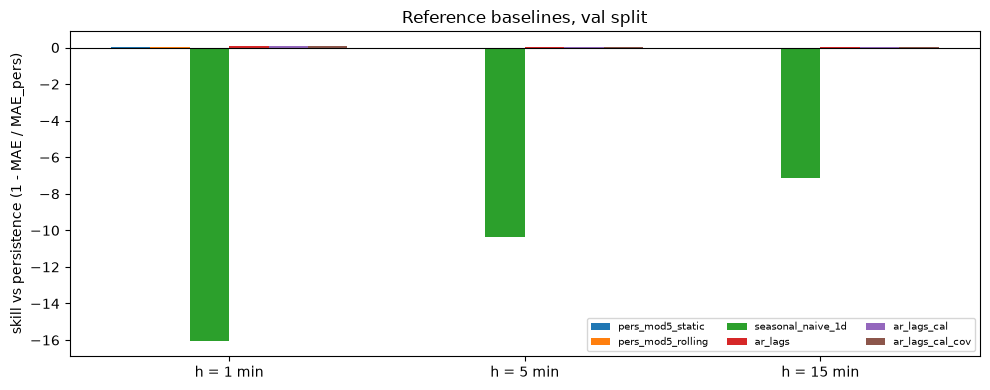

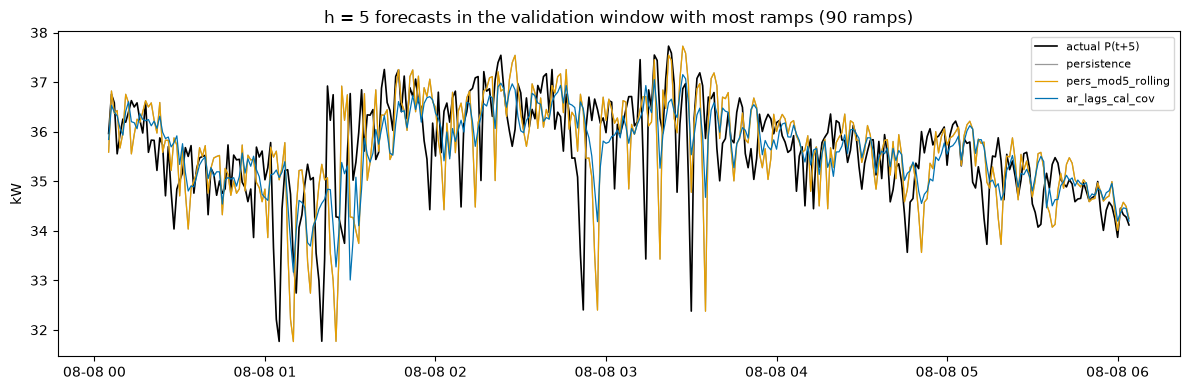

saved reports/figures/baselines/01_skill_val.png and reports/figures/baselines/02_window_h5.png


In [9]:
# Cell 9: figures: skill per model and horizon; one validation window (needs cell 8)
fig, ax = plt.subplots(figsize=(10, 4))
mods = [m for m in MODELS if m != "persistence"]
w = 0.8 / len(mods)
for i, mname in enumerate(mods):
    v = [VAL.filter((pl.col("h") == h) & (pl.col("model") == mname))["skill_MAE"][0] for h in HORIZONS]
    ax.bar(np.arange(len(HORIZONS)) + (i - (len(mods) - 1) / 2) * w, v, w, label=mname)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(HORIZONS)), [f"h = {h} min" for h in HORIZONS])
ax.set_ylabel("skill vs persistence (1 - MAE / MAE_pers)")
ax.set_title(f"Reference baselines, {SPLIT_EVAL} split")
ax.legend(fontsize=7, ncol=3)
fig.tight_layout(); fig.savefig(FIG / "01_skill_val.png", dpi=130); plt.show()

# 6-hour window of the validation split with the most p95 ramps at h = 5
h = 5
t = IDX[h][SPLIT_EVAL]
ramp = md[f"ramp_h{h}"].to_numpy().astype(float)[t]
blk = (t // 360)
ub, inv = np.unique(blk, return_inverse=True)
cnt = np.bincount(inv, weights=np.nan_to_num(ramp))
sel = inv == np.argmax(cnt)
fig, ax = plt.subplots(figsize=(12, 4))
tt = TLOC[t[sel] + h]
ax.plot(tt, P[t[sel] + h], lw=1.2, color="k", label="actual P(t+5)")
for mname, col in (("persistence", "#999999"), ("pers_mod5_rolling", "#e69f00"), ("ar_lags_cal_cov", "#0072b2")):
    ax.plot(tt, PRED[h][mname][sel], lw=0.9, color=col, label=mname)
ax.set_ylabel("kW"); ax.set_title(f"h = 5 forecasts in the validation window with most ramps ({int(cnt.max())} ramps)")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "02_window_h5.png", dpi=130); plt.show()
print("saved", (FIG / "01_skill_val.png").relative_to(ROOT), "and", (FIG / "02_window_h5.png").relative_to(ROOT))


In [10]:
# Cell 10: save tables, predictions and a summary; optional W&B (needs cell 8)
VAL.write_csv(OUT / "val_metrics.csv")
H3.write_csv(OUT / "val_h3_covariates.csv")
parts = []
for h in HORIZONS:
    t = IDX[h][SPLIT_EVAL]
    base = {"minute_epoch": md["minute_epoch"].to_numpy()[t], "h": np.full(len(t), h, np.int16),
            "y": P[t + h], "p0": P[t], "l24": L24[t], "mod5": MOD5[t].astype(np.int8),
            "ramp": md[f"ramp_h{h}"].to_numpy().astype(float)[t]}
    for mname in MODELS:
        parts.append(pl.DataFrame({**base, "model": [mname] * len(t), "yhat": PRED[h][mname]}))
pl.concat(parts).write_parquet(OUT / "val_predictions.parquet")
summary = {"split": SPLIT_EVAL, "dataset_builder": meta["version"], "dataset_input_sha256": meta["input"]["sha256"],
           "created": time.strftime("%Y-%m-%d %H:%M:%S"), "dm_lag": DM_LAG, "roll_window_min": ROLL_WINDOW,
           "alphas": ALPHAS, "chosen_alpha": {f"{h}|{m}": v["alpha"] for (h, m), v in AR_INFO.items()},
           "metrics": VAL.to_dicts(), "h3": H3.to_dicts()}
(OUT / "baselines_summary.json").write_text(json.dumps(summary, indent=1, default=str))
for f in ("val_metrics.csv", "val_h3_covariates.csv", "val_predictions.parquet", "baselines_summary.json"):
    print(f"written reports/baselines/{f} ({(OUT / f).stat().st_size / 2**20:.2f} MiB)")

if USE_WANDB:
    import wandb
    run = wandb.init(project="dcpower", name="baselines_val", job_type="baselines",
                     config={"split": SPLIT_EVAL, "alphas": ALPHAS, "dm_lag": DM_LAG, "dataset": meta["version"]})
    run.log({"val_metrics": wandb.Table(dataframe=VAL.to_pandas())})
    run.finish()
    print("logged to W&B")


written reports/baselines/val_metrics.csv (0.01 MiB)
written reports/baselines/val_h3_covariates.csv (0.00 MiB)
written reports/baselines/val_predictions.parquet (17.45 MiB)
written reports/baselines/baselines_summary.json (0.01 MiB)


In [11]:
# Cell 11: summary (needs cells 3, 8 and 10)
print(f"split {SPLIT_EVAL} | test not opened | metrics self-test ok: {METRICS_OK}")
for h in HORIZONS:
    v = VAL.filter(pl.col("h") == h)
    pers = v.filter(pl.col("model") == "persistence")["MAE"][0]
    b = v.filter(pl.col("model") != "persistence").sort("MAE").row(0, named=True)
    h3 = H3.filter(pl.col("h") == h).row(0, named=True)
    print(f"h={h:>2}: persistence MAE {pers:.4f} kW | best {b['model']} {b['MAE']:.4f} kW "
          f"(skill {b['skill_MAE']:+.3f}, DM p {b['DM_p']:.2g}) | covariates change MAE by {h3['rel. change']:+.2%} "
          f"(DM p {h3['DM p']:.2g})")


split val | test not opened | metrics self-test ok: True
h= 1: persistence MAE 0.2866 kW | best ar_lags_cal_cov 0.2637 kW (skill +0.080, DM p 5.8e-14) | covariates change MAE by -1.52% (DM p 3.6e-06)
h= 5: persistence MAE 0.4299 kW | best ar_lags_cal_cov 0.4090 kW (skill +0.049, DM p 9.3e-10) | covariates change MAE by -1.75% (DM p 1.3e-06)
h=15: persistence MAE 0.6048 kW | best ar_lags_cal_cov 0.5786 kW (skill +0.043, DM p 4.7e-10) | covariates change MAE by -1.42% (DM p 2.1e-06)


In [12]:
%run ../src/tools/nb_outputs_to_md.py 07_baselines.ipynb

written 07_baselines_outputs.md | code cells 13 | figures 2 in 07_baselines_outputs_figures
